/tmp/ipykernel_1580086/2656451811.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_heatmap = sub_adata.to_df().groupby(sub_adata.obs['celltype']).mean()


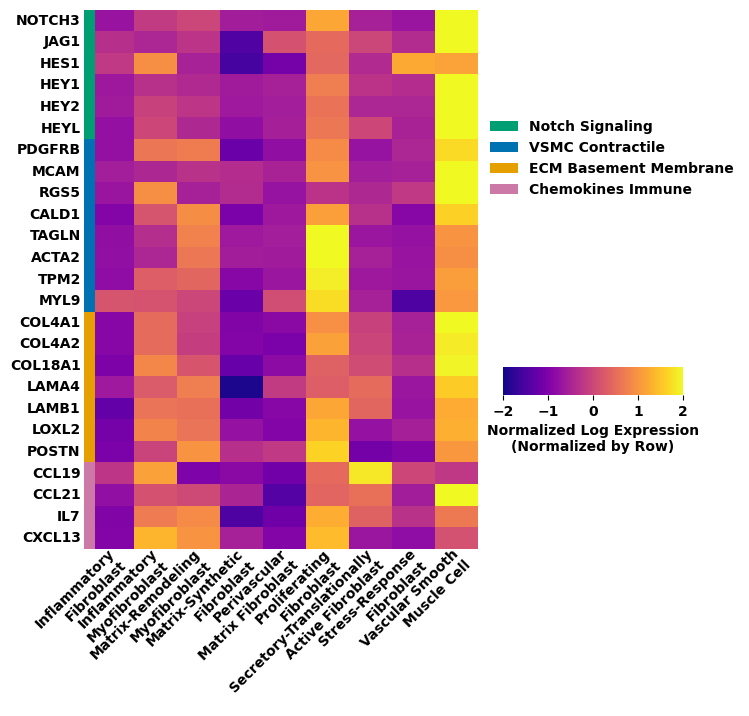

In [6]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.transforms as mtransforms
from matplotlib.colors import LinearSegmentedColormap

# 1. 读取数据
adata = sc.read("./h5ad/adata_fibroblast.h5ad")

# 确保 celltype 列是分类类型，并使用数据中定义的 Category 顺序
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
categories = adata.obs['celltype'].cat.categories.tolist()

# 定义需要展示的基因列表
genes_of_interest = [
    "NOTCH3", "JAG1", "HES1", "HEY1", "HEY2", "HEYL",
    "PDGFRB", "MCAM", "RGS5", "CALD1", "TAGLN", "ACTA2", "TPM2", "MYL9",
    "COL4A1", "COL4A2", "COL18A1", "LAMA4", "LAMB1", "LOXL2", "POSTN",
    "CCL19", "CCL21", "IL7", "CXCL13"
]

# 2. 数据预处理：1e6归一化与Log转换
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
existing_genes = [g for g in genes_of_interest if g in adata.var_names]
sub_adata = adata[:, existing_genes].copy()

# 3. 按 celltype 计算分组平均值
df_heatmap = sub_adata.to_df().groupby(sub_adata.obs['celltype']).mean()
df_heatmap = df_heatmap.T

#4. 归一化
df_heatmap_zscore = df_heatmap.apply(lambda x: (x - x.mean()) / x.std(), axis=1)

# 5. 按照 Category 顺序排列 X 轴
df_heatmap_zscore = df_heatmap_zscore[categories]
df_heatmap_zscore.columns.name = None
def replace_center_space(name):
    spaces = [i for i, c in enumerate(name) if c == ' ']
    if not spaces:
        return name
    center = len(name) / 2
    closest = min(spaces, key=lambda x: abs(x - center))
    return name[:closest] + '\n' + name[closest+1:]

df_heatmap_zscore.columns = [replace_center_space(c) for c in df_heatmap_zscore.columns]
# 6. 定义 Pathway 颜色标签
pathway_info = {
    "Notch Signaling": {"color": "#009E73", "genes": ["NOTCH3", "JAG1", "HES1", "HEY1", "HEY2", "HEYL"]},
    "VSMC Contractile": {"color": "#0072B2", "genes": ["PDGFRB", "MCAM", "RGS5", "CALD1", "TAGLN", "ACTA2", "TPM2", "MYL9"]},
    "ECM Basement Membrane": {"color": "#E69F00", "genes": ["COL4A1", "COL4A2", "COL18A1", "LAMA4", "LAMB1", "LOXL2", "POSTN"]},
    "Chemokines Immune": {"color": "#CC79A7", "genes": ["CCL19", "CCL21", "IL7", "CXCL13"]}
}

# 生成左侧颜色条
row_colors = []
for gene in df_heatmap_zscore.index:
    added = False
    for pathway, info in pathway_info.items():
        if gene in info["genes"]:
            row_colors.append(info["color"])
            added = True
            break
    if not added:
        row_colors.append("#D3D3D3")

# 7. 画布
fig, ax = plt.subplots(figsize=(5, 7))

# 绘制热图 (隐藏自带颜色条)
g = sns.heatmap(
    df_heatmap_zscore,
    cmap="plasma",
    vmin=-2,
    vmax=2,
    cbar=False,
    xticklabels=True,
    yticklabels=True
)

# 8. 添加左侧 Pathway 颜色块
for i, color in enumerate(row_colors):
    ax.add_patch(plt.Rectangle((-0.15, i), 0.25, 1, facecolor=color, transform=ax.transData, clip_on=False))

# 美化排版
ax.tick_params(axis='x', which='major', pad=-5)
plt.xticks(x=np.arange(len(categories)) + 50,rotation=45, ha='right', fontsize=9)
ax.tick_params(axis='y', left=False)
ax.tick_params(axis='x', bottom=False)

dx = 12  # 单位：points；越大越右移，可改成 8、10、15 试
offset = mtransforms.ScaledTranslation(dx / 72.0, 0, fig.dpi_scale_trans)

for label in ax.get_xticklabels():
    label.set_transform(label.get_transform() + offset)

# 9. 在右侧边缘放置横向颜色条
cbar_ax = fig.add_axes([0.95, 0.33, 0.36, 0.04])
fig.colorbar(ax.collections[0], cax=cbar_ax, orientation='horizontal')
cbar_ax.set_xlabel('Normalized Log Expression\n(Normalized by Row)',
                   fontweight='bold', fontsize=10)
cbar_ax.tick_params(labelsize=10)
for label in cbar_ax.get_xticklabels():
    label.set_fontweight('bold')
cbar_ax.yaxis.set_ticks_position('right')
cbar_ax.yaxis.set_label_position('right')
for spine in cbar_ax.spines.values():
    spine.set_visible(False)

# 10. 在颜色条上方添加单列图例
legend_ax = fig.add_axes([0.90, 0.19, 0.06, 0.55])
legend_ax.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=info["color"]) for info in pathway_info.values()]
labels = list(pathway_info.keys())
legend = legend_ax.legend(handles, labels, loc='upper left', frameon=False, fontsize=10, columnspacing=1.0)
for text in legend.get_texts():
    text.set_fontweight("bold")

# 加粗行名（Y轴）
for label in ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(10)

# 加粗列名（X轴）
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(10)
    
plt.show()